# **HW 7**

# Problem 3 Write - Up


Using Chebyshev points instead of equally spaced points, we can see that the end points are much more stable at higher N values, unlike in problems 1 and 2. This polynomial becomes a better approximation of our function since it does not display Runge's phenomenon .


Problem 1-3 all below, just thought I should put the write up for 3 up here so it didnt get lost!

## **Problem 1**

In [8]:
import numpy as np
import math
import matplotlib.pyplot as plt

In [26]:
def interpolate(xvals, func):
    yvals = func(xvals)
    n = len(xvals)
    V = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            V[i, j] = xvals[i]**(n-1-j)
            
    c = np.linalg.inv(V) @ yvals
    return c

In [210]:
#TEST
f = lambda x: x**8 + 5
xvals = np.array([1., 2., 3., 4., 5., 6., 7.])
interpolate(xvals, f)

array([    462.        ,   -7056.        ,   48111.        ,
       -176400.        ,  354628.00000002, -360864.00000002,
        141125.00000001])

Find the polynomial (i.e. the coefficients c) that interpolates
f(x) = 1
1 + (10x)
2
,
in the points xi = −1 + (i − 1)h, h =
2
N−1
, i = 1, . . . , N. Plot data points as circles
(plot(x,f,’o’)) and, in the same plot, plot the polynomial and f(x) on a finer grid
(still on x ∈ [−1, 1]), say with 1001 points. Observe what happens when you increase N.
Try N = 2, 3, 4, . . . and continue until the maximum value of p(x) is about 100 (should
be for N ∼ 17 − 20). 

In [103]:
def interpolate(xvals, func):
    yvals = func(xvals)
    n = len(xvals)
    V = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            V[i, j] = xvals[i]**(n-1-j)
            
    c = np.linalg.inv(V) @ yvals
    return c


f = lambda x: 1 / (1 + 100*x**2)


def gen_xvals(N):
    xvals = np.zeros(N)
    for n in range(1, N + 1):
        h = 2/ (N-1)
        i = n
        xvals[n-1] = -1 + (i - 1)*h
        
    return xvals



def plot(Ns, func):
    for N in Ns:
        plt.figure()
        
        x = gen_xvals(N)
        true = np.linspace(-1, 1, 1001)
        plt.plot(true, func(true), label='True function', color='xkcd:lime')
        c = interpolate(x, func)

        p = np.zeros(len(true))
        for n in range(N):
            p = p + c[n]*true**(N-1-n)

        plt.plot(true, p, label='Interpolation', color='xkcd:lightblue')
        plt.plot(x, func(x), 'o', label='Points', color='xkcd:black', markersize=2)
        plt.title(f'Interpolation with {N} points')
        plt.legend()

    plt.show()

    return


In [69]:
interpolate(gen_xvals(5), f)

array([ 3.80807312e+00,  1.36831324e-18, -4.79817212e+00,  9.58964298e-19,
        1.00000000e+00])

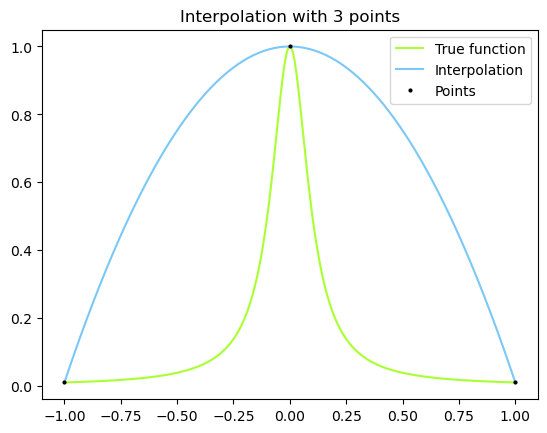

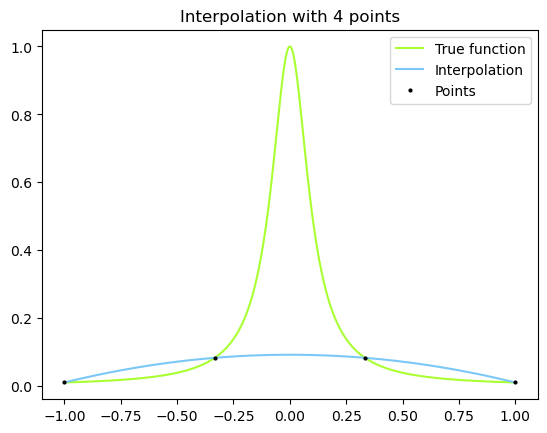

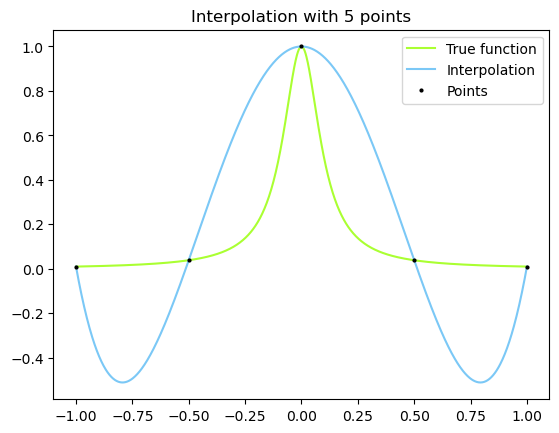

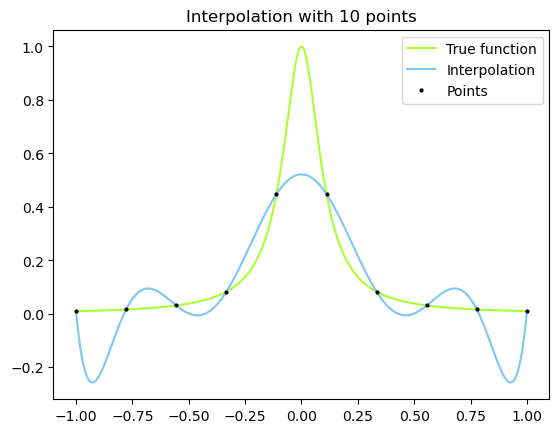

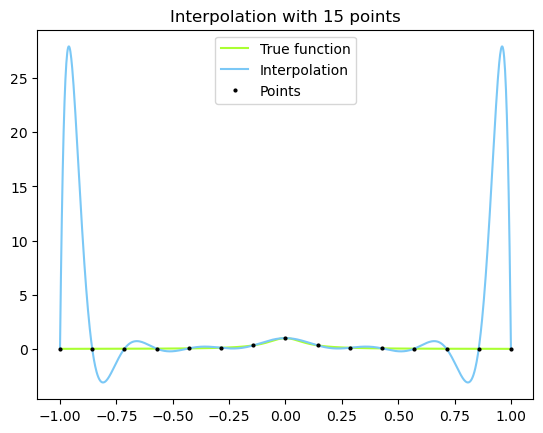

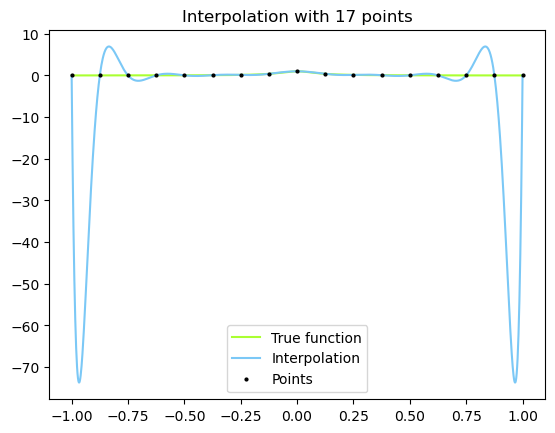

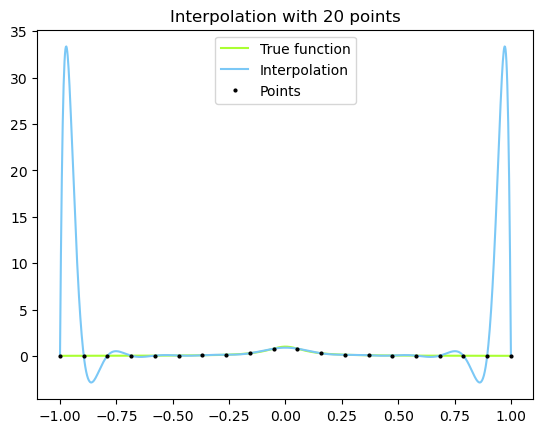

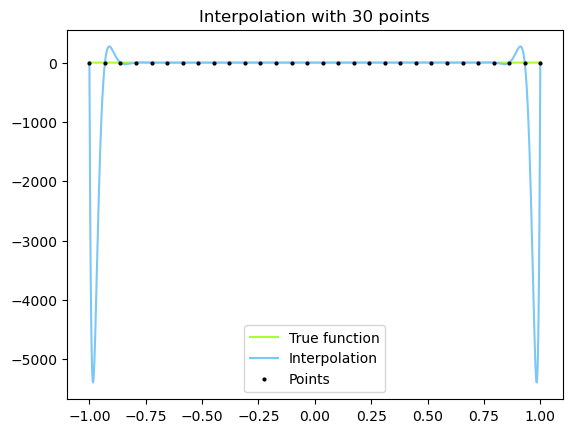

In [111]:
plot(np.array([3, 4, 5, 10, 15, 17, 20, 30]), f)

## **Problem 2**

In [132]:
def gen_w(xvals, i):
    n = len(xvals)
    w = 1
    for num in range(n):
        if num != i:
            w = w * (xvals[i] - xvals[num]) ** (-1)
    return w

def polynomial_2(x, xvals, func):
    top = 0
    bottom = 0

    n = len(xvals)
    for i in range(n):
        if x == xvals[i]:
            return func(xvals[i])

        
        top += (gen_w(xvals, i) * func(xvals[i])) / (x - xvals[i])
        bottom += (gen_w(xvals, i)) / (x - xvals[i])

    return top / bottom


def poly_plot(Ns, func):
    for N in Ns:
        plt.figure()
        
        xvals = gen_xvals(N)
        true = np.linspace(-1, 1, 1001)
        plt.plot(true, func(true), label='True function', color='xkcd:pink')

        bary = np.zeros(len(true))
        for i in range(len(true)):
            bary[i] = polynomial_2(true[i], xvals, f)
        
        plt.plot(true, bary, label='Barycentric', color='xkcd:lightblue')
        plt.plot(xvals, func(xvals), 'o', label='Points', color='xkcd:black', markersize=2)
        plt.title(f'Barycentric Lagrange Interpolation with {N} points')
        plt.legend()

    plt.show()

    return

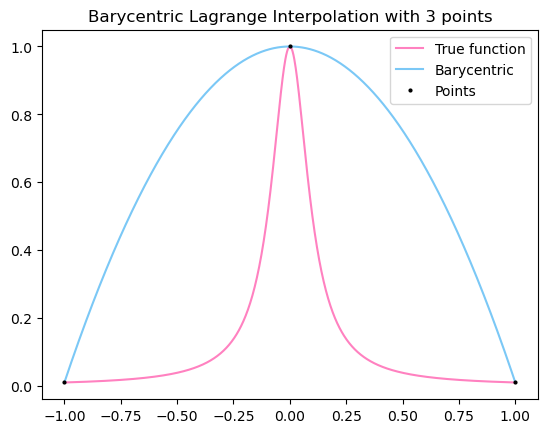

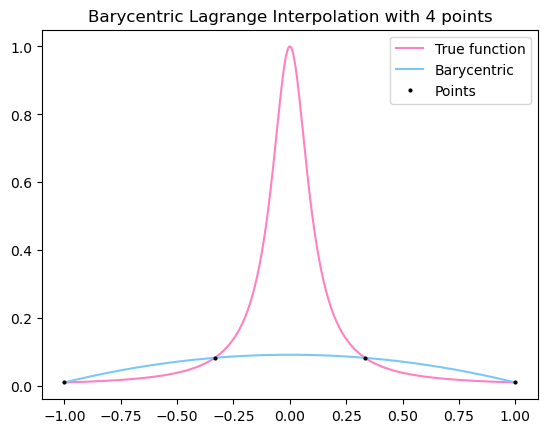

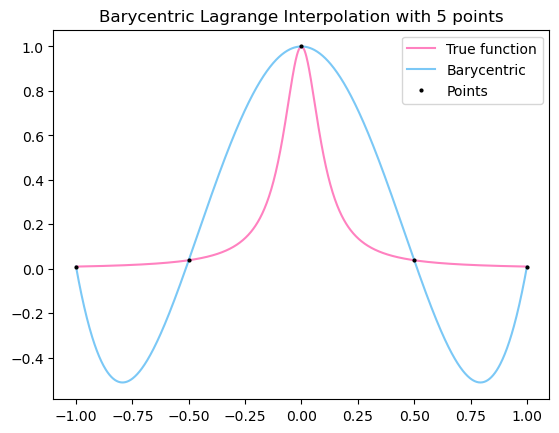

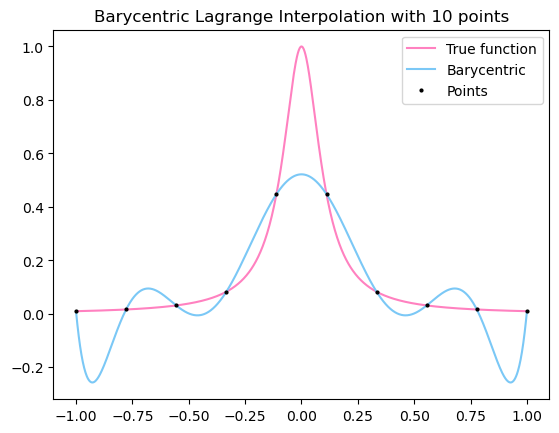

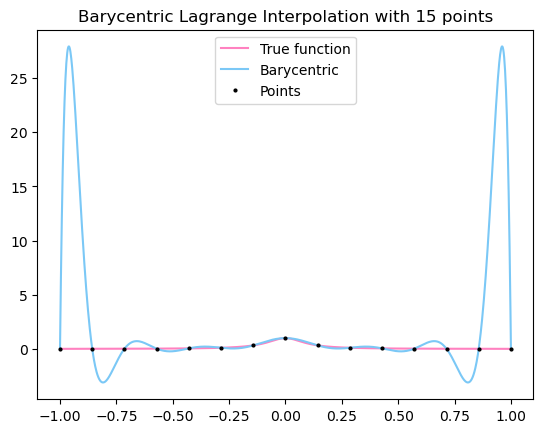

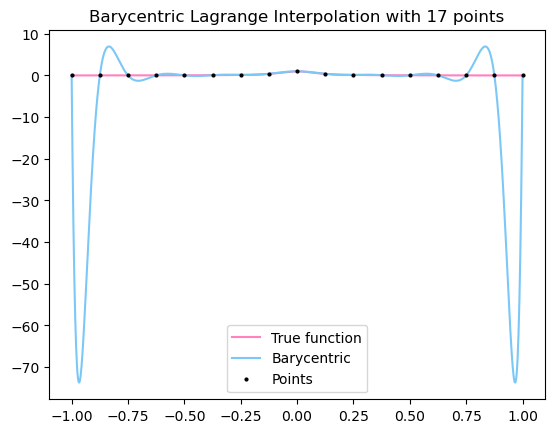

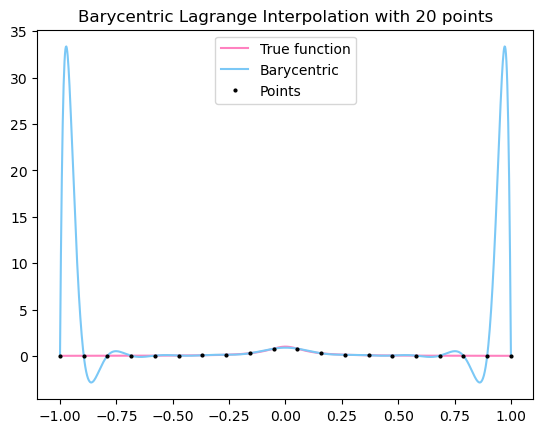

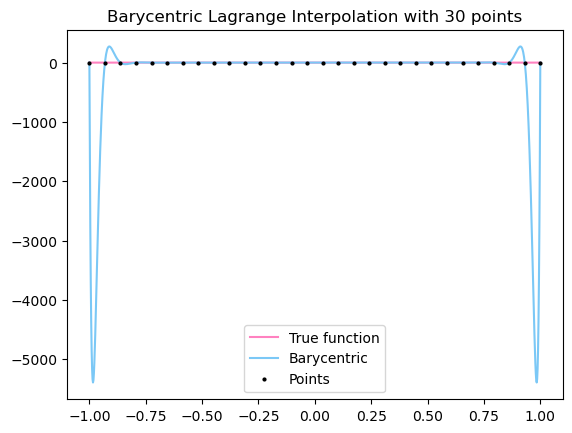

In [134]:
poly_plot(np.array([3, 4, 5, 10, 15, 17, 20, 30]), f)

## **Problem 3**

Generate xvals differently

In [169]:
def diff_gen_xvals(N):
    xvals = np.zeros(N)

    for i in range(1, N+1):
        xvals[i-1] = np.cos(((2*i - 1) * np.pi) / (2*N))
        
    return xvals

In [159]:
diff_gen_xvals(5)

array([ 9.51056516e-01,  5.87785252e-01,  6.12323400e-17, -5.87785252e-01,
       -9.51056516e-01])

### **Problem 1 Equation**

In [193]:
def interpolate(xvals, func):
    yvals = func(xvals)
    n = len(xvals)
    V = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            V[i, j] = xvals[i]**(n-1-j)
            
    c = np.linalg.inv(V) @ yvals
    return c

f = lambda x: 1 / (1 + 100*x**2)

def plot_diff(Ns, func):
    for N in Ns:
        plt.figure()
        
        x = diff_gen_xvals(N)
        true = np.linspace(-1, 1, 1001)
        plt.plot(true, func(true), label='True function', color='xkcd:purple')
        c = interpolate(x, func)

        p = np.zeros(len(true))
        for n in range(N):
            p = p + c[n]*true**(N-1-n)

        plt.plot(true, p, label='Interpolation', color='xkcd:lightgreen')
        plt.plot(x, func(x), 'o', label='Points', color='xkcd:black', markersize=2)
        plt.title(f'Interpolation with {N} points')
        plt.legend()

    plt.show()

    return


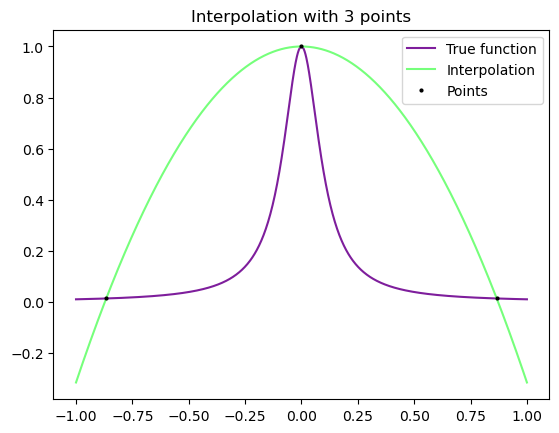

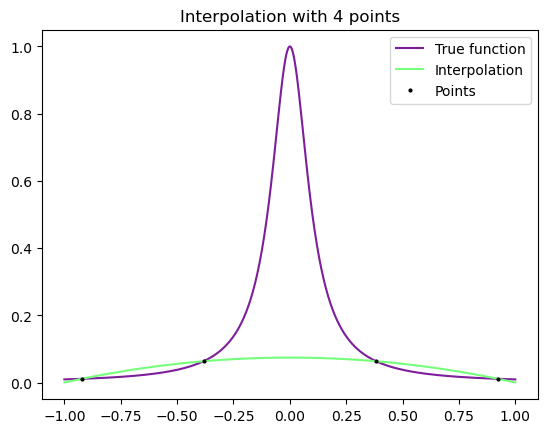

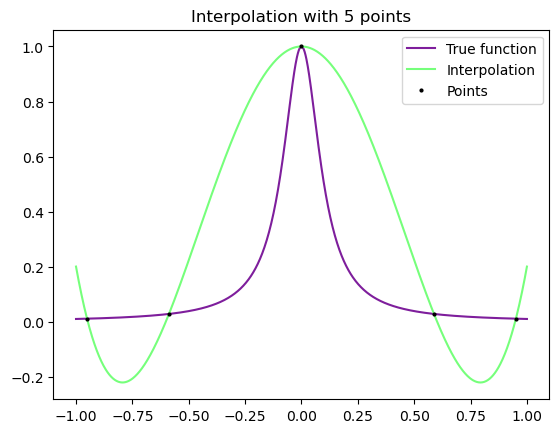

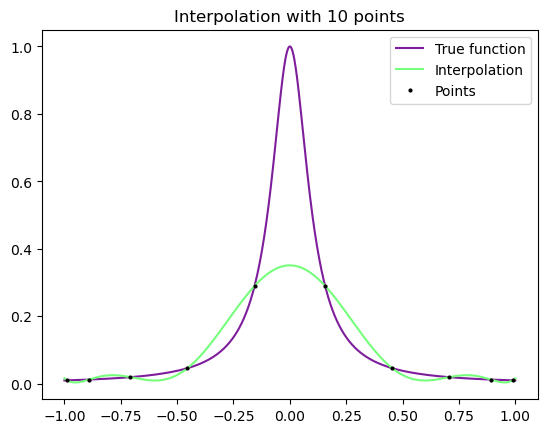

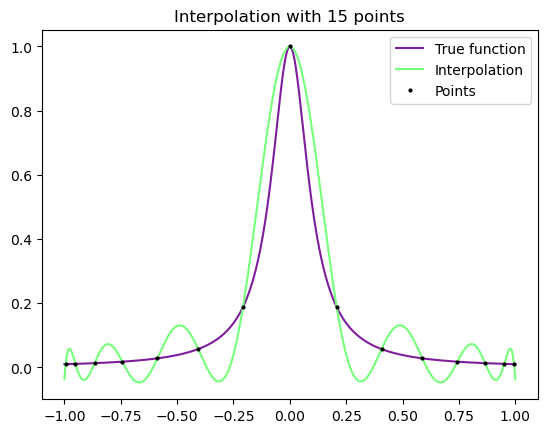

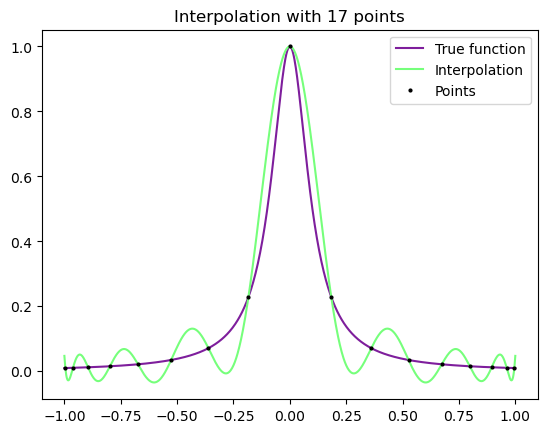

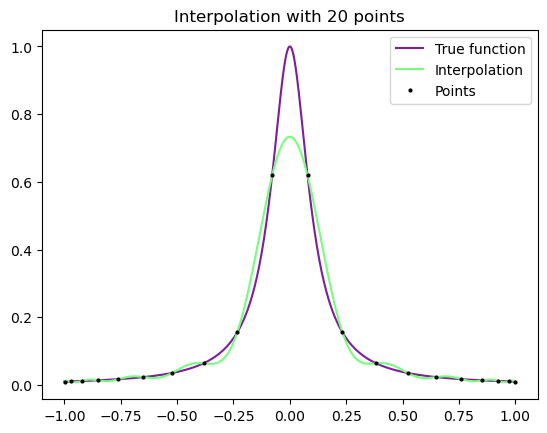

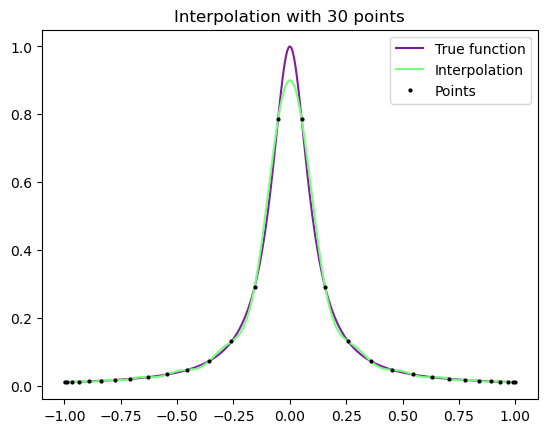

In [195]:
plot_diff(np.array([3, 4, 5, 10, 15, 17, 20, 30]), f)

### **Problem 2 Equation**

In [201]:
def gen_w(xvals, i):
    n = len(xvals)
    w = 1
    for num in range(n):
        if num != i:
            w = w * (xvals[i] - xvals[num]) ** (-1)
    return w

def polynomial_2(x, xvals, func):
    top = 0
    bottom = 0

    n = len(xvals)
    for i in range(n):
        if x == xvals[i]:
            return func(xvals[i])

        
        top += (gen_w(xvals, i) * func(xvals[i])) / (x - xvals[i])
        bottom += (gen_w(xvals, i)) / (x - xvals[i])

    return top / bottom


def poly_plot_diff(Ns, func):
    for N in Ns:
        plt.figure()
        
        xvals = diff_gen_xvals(N)
        true = np.linspace(-1, 1, 1001)
        plt.plot(true, func(true), label='True function', color='xkcd:darkgreen')

        bary = np.zeros(len(true))
        for i in range(len(true)):
            bary[i] = polynomial_2(true[i], xvals, f)
        
        plt.plot(true, bary, label='Barycentric', color='xkcd:gold')
        plt.plot(xvals, func(xvals), 'o', label='Points', color='xkcd:black', markersize=2)
        plt.title(f'Barycentric Lagrange Interpolation with {N} points')
        plt.legend()

    plt.show()

    return

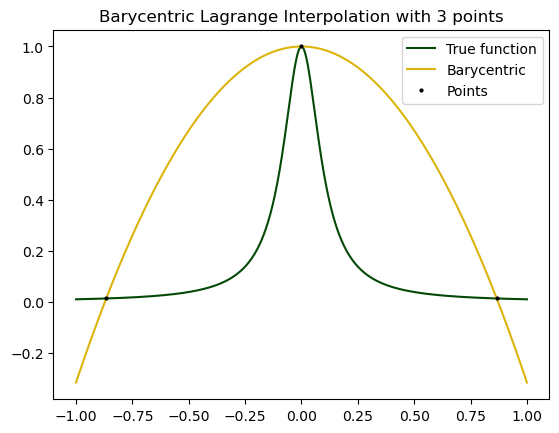

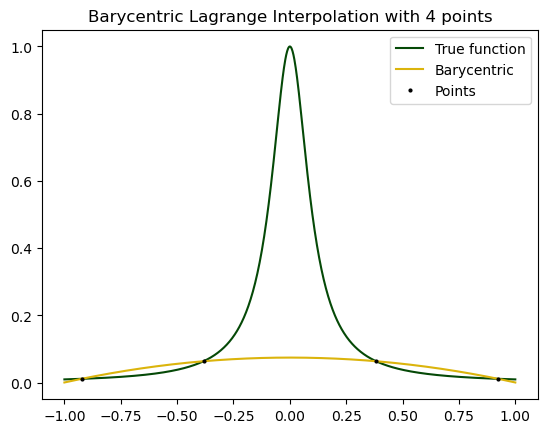

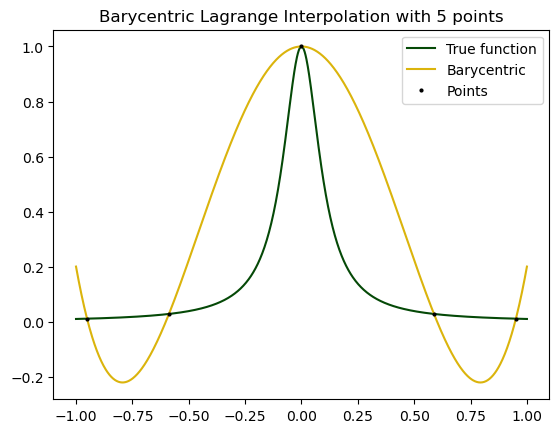

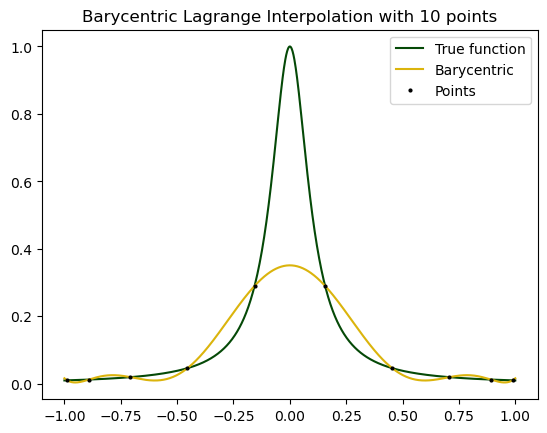

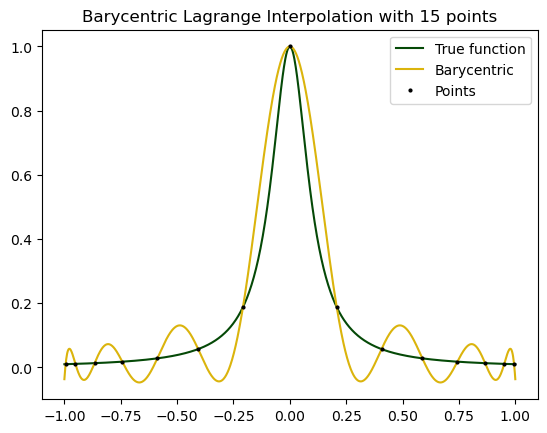

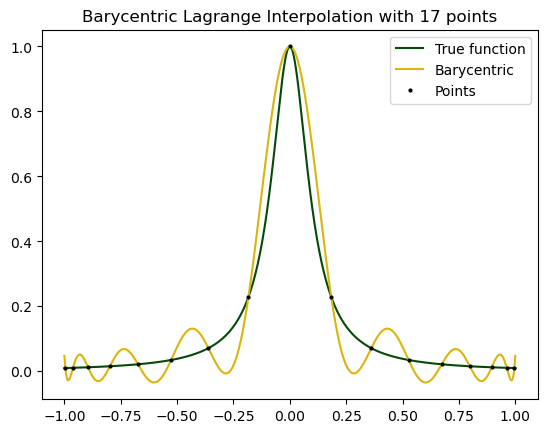

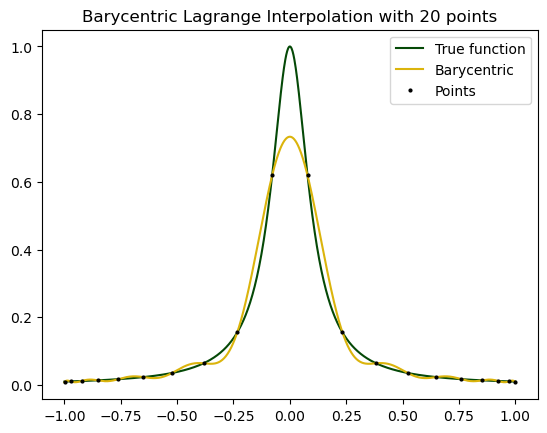

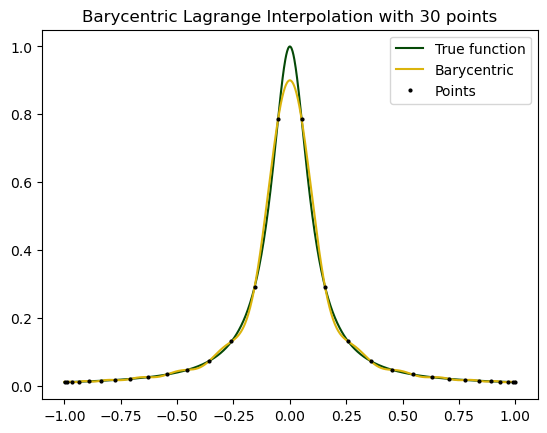

In [203]:
poly_plot_diff(np.array([3, 4, 5, 10, 15, 17, 20, 30]), f)

# Problem 3 Write - Up


Using Chebyshev points instead of equally spaced points, we can see that the end points are much more stable at higher N values, unlike in problems 1 and 2. This polynomial becomes a better approximation of our function since it does not display Runge's phenomenon .